# Decomposing Private Equity

**FINM 36700 · Group:** Lucas Albín Lazcano, Avi Rastogi, Mengting Wang, Yihan Kong

Use the data in `../data/private_equity_data.xlsx`

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

FREQ = 52

Matplotlib is building the font cache; this may take a moment.


In [2]:
LOADFILE = 'private_equity_data.xlsx'
info = pd.read_excel(LOADFILE,sheet_name='descriptions').set_index('ticker')
rets = pd.read_excel(LOADFILE,sheet_name='total returns').set_index('date')
retsx = pd.read_excel(LOADFILE,sheet_name='excess returns').set_index('date')

In [3]:
info[['shortName','quoteType']]

,shortName,quoteType
ticker,,
SPY,SPDR S&P 500,ETF
VTV,Vanguard Value ETF,ETF
AGG,iShares Core U.S. Aggregate Bon,ETF
HYG,iShares iBoxx $ High Yield Corp,ETF
IEF,iShares 7-10 Year Treasury Bond,ETF
PSP,Invesco Global Listed Private E,ETF
PEX,ProShares Global Listed Private,ETF
APO,"Apollo Global Management, Inc.",EQUITY
BX,Blackstone Inc.,EQUITY


In [4]:
display(rets.head().style.format('{:.1%}').format_index('{:%Y-%m-%d}'))
display(rets.tail().style.format('{:.1%}').format_index('{:%Y-%m-%d}'))

,SPY,VTV,AGG,HYG,IEF,PSP,PEX,APO,BX,KKR,CG,SHV
date,,,,,,,,,,,,
2015-01-09,-0.6%,-0.7%,0.5%,0.6%,1.4%,-0.7%,-0.6%,1.3%,0.2%,1.1%,-5.7%,0.0%
2015-01-16,-1.3%,-1.2%,0.4%,-0.6%,1.0%,-1.4%,-1.1%,0.3%,-1.6%,-3.3%,-6.4%,0.0%
2015-01-23,1.7%,1.2%,0.2%,0.5%,0.2%,2.0%,0.9%,2.8%,7.1%,5.7%,3.2%,0.0%
2015-01-30,-2.7%,-3.4%,0.6%,0.2%,1.2%,-0.1%,0.9%,1.0%,3.5%,-1.0%,2.5%,-0.0%
2015-02-06,3.1%,3.8%,-1.2%,0.8%,-2.4%,2.7%,2.9%,-2.3%,-3.4%,3.0%,1.2%,0.0%


,SPY,VTV,AGG,HYG,IEF,PSP,PEX,APO,BX,KKR,CG,SHV
date,,,,,,,,,,,,
2025-09-05,0.3%,-0.4%,0.6%,0.0%,0.7%,-1.3%,-0.7%,-3.4%,-0.8%,-2.8%,-1.3%,-0.2%
2025-09-12,1.6%,1.3%,0.4%,0.1%,0.2%,1.9%,-0.1%,4.9%,6.7%,5.8%,4.5%,0.1%
2025-09-19,1.0%,0.4%,-0.2%,0.4%,-0.4%,0.3%,-1.2%,4.9%,3.5%,3.9%,2.4%,0.1%
2025-09-26,-0.3%,0.5%,-0.2%,-0.2%,-0.4%,-3.8%,-4.9%,-4.9%,-6.6%,-10.0%,-6.1%,0.1%
2025-10-03,0.3%,-0.4%,0.2%,0.2%,0.3%,0.4%,0.2%,0.6%,0.5%,0.4%,1.4%,0.0%


# 1. Performance

Calculate performance stats for the assets, both stand-alone (mean, vol, Sharpe) as well as linear decompositions (alpha, beta, info ratio, r-squared).

We use **excess returns** (over `SHV`, short treasuries) so that Sharpe ratios and alphas are measured relative to the risk-free rate. The linear decomposition is against the market, `SPY`:

$$\tilde{r}^i_t = \alpha + \beta\,\tilde{r}^{SPY}_t + \epsilon_t$$

All statistics are annualized with 52 weeks per year. The information ratio is $\alpha / \sigma_\epsilon$.

In [5]:
def performance_stats(rets, bench, freq=FREQ):
    out = {}
    for col in rets.columns:
        y = rets[col]
        mod = sm.OLS(y, sm.add_constant(bench)).fit()
        alpha = mod.params['const'] * freq
        resid_vol = mod.resid.std() * np.sqrt(freq)
        out[col] = {
            'Mean': y.mean() * freq,
            'Vol': y.std() * np.sqrt(freq),
            'Sharpe': y.mean() / y.std() * np.sqrt(freq),
            'Alpha': alpha,
            'Beta': mod.params[bench.name],
            'Info Ratio': alpha / resid_vol if resid_vol > 1e-8 else np.nan,
            'R-squared': mod.rsquared,
        }
    return pd.DataFrame(out).T

perf = performance_stats(retsx, retsx['SPY'])
perf.style.format({'Mean':'{:.1%}','Vol':'{:.1%}','Sharpe':'{:.2f}','Alpha':'{:.1%}',
                   'Beta':'{:.2f}','Info Ratio':'{:.2f}','R-squared':'{:.1%}'})

,Mean,Vol,Sharpe,Alpha,Beta,Info Ratio,R-squared
SPY,12.3%,17.0%,0.73,-0.0%,1.00,nan,100.0%
VTV,8.6%,16.4%,0.53,-2.4%,0.90,-0.39,85.9%
AGG,-0.8%,5.1%,-0.15,-1.6%,0.07,-0.32,4.8%
HYG,-0.5%,9.5%,-0.05,-5.7%,0.42,-0.91,56.9%
IEF,-0.7%,6.4%,-0.11,-0.4%,-0.03,-0.06,0.5%
PSP,4.9%,23.2%,0.21,-9.6%,1.18,-0.83,74.8%
PEX,-1.4%,21.5%,-0.07,-13.5%,0.98,-0.99,59.7%
APO,23.2%,36.8%,0.63,4.9%,1.48,0.18,46.6%
BX,21.8%,35.8%,0.61,3.7%,1.46,0.14,48.1%
KKR,22.9%,36.5%,0.63,3.5%,1.57,0.14,53.6%


# 2. Replication

Can we replicate private equity `APO` using the following?
* public equity `SPY`
* treasury bonds `IEF`
* high-yield corp bonds `HYG`

How does that compare to `APO` against `SPY` alone?

We regress `APO` excess returns on the factor excess returns, with an intercept, and compare:
1. `SPY` only
2. `SPY`, `IEF`, `HYG`

In [6]:
def regress(y, X, freq=FREQ):
    mod = sm.OLS(y, sm.add_constant(X)).fit()
    alpha = mod.params['const'] * freq
    te = mod.resid.std() * np.sqrt(freq)
    est = pd.concat([mod.params, mod.tvalues], axis=1, keys=['coef', 't-stat'])
    est.loc['const', 'coef'] *= freq   # annualize alpha
    summary = pd.Series({'Alpha (ann.)': alpha, 'R-squared': mod.rsquared,
                         'Tracking error (ann.)': te, 'Info Ratio': alpha / te})
    return mod, est, summary

y = retsx['APO']
models = {'SPY only': ['SPY'], 'SPY + IEF + HYG': ['SPY', 'IEF', 'HYG']}
fits, summaries = {}, {}
for name, X in models.items():
    mod, est, summ = regress(y, retsx[X])
    fits[name] = mod
    summaries[name] = summ
    print(name)
    display(est.rename(index={'const': 'alpha (ann.)'}).style.format('{:.3f}'))

pd.DataFrame(summaries).style.format('{:.3f}')

SPY only


,coef,t-stat
alpha (ann.),0.049,0.599
SPY,1.480,22.086


SPY + IEF + HYG


,coef,t-stat
alpha (ann.),0.100,1.233
SPY,1.066,10.429
IEF,-0.704,-3.957
HYG,0.931,5.106


,SPY only,SPY + IEF + HYG
Alpha (ann.),0.049,0.100
R-squared,0.466,0.497
Tracking error (ann.),0.269,0.261
Info Ratio,0.184,0.382


Correlations among the factors matter for interpreting the betas:

In [7]:
retsx[['APO','SPY','IEF','HYG']].corr().style.format('{:.2f}')

,APO,SPY,IEF,HYG
APO,1.00,0.68,-0.13,0.60
SPY,0.68,1.00,-0.07,0.75
IEF,-0.13,-0.07,1.00,0.11
HYG,0.60,0.75,0.11,1.00


Cumulative returns of `APO` against its two fitted replications (fitted values *excluding* the intercept, i.e. the pure factor portfolios):

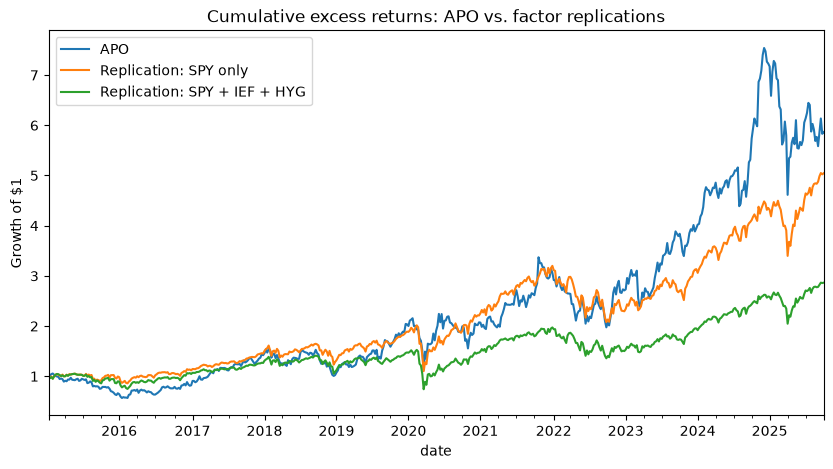

In [8]:
rep = pd.DataFrame({'APO': y})
for name, X in models.items():
    rep[f'Replication: {name}'] = retsx[X] @ fits[name].params[X]

(1 + rep).cumprod().plot(figsize=(10, 5), title='Cumulative excess returns: APO vs. factor replications')
plt.ylabel('Growth of $1')
plt.show()

### Out-of-sample check

To see whether the extra factors help beyond in-sample fit, we estimate each replication on a rolling 2-year (104-week) window and use the betas (no intercept) to predict the next week's `APO` return. Out-of-sample R² is $1 - \sum (y - \hat{y})^2 / \sum y^2$ (benchmark: a zero-return forecast).

In [9]:
WINDOW = 104
oos = {}
for name, X in models.items():
    preds = pd.Series(index=y.index, dtype=float)
    for t in range(WINDOW, len(y)):
        Xw, yw = retsx[X].iloc[t-WINDOW:t], y.iloc[t-WINDOW:t]
        b = sm.OLS(yw, sm.add_constant(Xw)).fit().params[X]
        preds.iloc[t] = retsx[X].iloc[t] @ b
    e = (y - preds).dropna()
    oos[name] = 1 - (e**2).sum() / (y.loc[e.index]**2).sum()

pd.Series(oos, name='OOS R-squared').to_frame().style.format('{:.1%}')

,OOS R-squared
SPY only,47.1%
SPY + IEF + HYG,51.6%


**Answer**

* **`SPY` alone** explains about 47% of `APO`'s variation, with a beta of ~1.5: `APO` behaves like a leveraged equity position. The remaining tracking error is large (~27% annualized).
* **Adding `IEF` and `HYG`** improves the fit only modestly (R² rises to roughly 50%). Both new betas are statistically significant: a **positive** loading on high yield (~0.9) and a **negative** loading on treasuries (~-0.7). The equity beta falls to ~1.1 because `HYG` is highly correlated with `SPY` (~0.75) and takes over part of the equity exposure.
* Long `HYG` / short `IEF` is essentially a **credit spread** position. This fits private equity's economics: leveraged buyouts depend on credit markets, and PE returns are hurt when spreads widen.
* **Can we replicate `APO`?** Only partly. The factor portfolio captures the systematic equity and credit exposure (about half the variance), but roughly half of `APO`'s variance is idiosyncratic and cannot be replicated with these liquid instruments. Out of sample (rolling 104-week betas), the 3-factor replication still does better than `SPY` alone (OOS R² of about 52% vs. 47%), so the credit exposure is a real and fairly stable feature of `APO`, not just in-sample overfitting.
* The alpha is still positive and slightly larger in the 3-factor model (because of the negative `IEF` loading, during a sample with poor treasury returns), but it is not statistically significant (t-stat ~1.2).